# Customer Churn Prediction System

An End-to-End Machine Learning System for Predicting Customer Churn

## Objectives
- Perform data validation and exploratory data analysis
- Engineer meaningful customer behavior features
- Benchmark multiple machine learning models
- Handle class imbalance
- Optimize hyperparameters
- Optimize classification threshold
- Perform error analysis
- Explain predictions using SHAP
- Track experiments with MLflow
- Build a production-ready inference pipeline
- Deploy the final model through FastAPI

#**Install Libraries**

In [ ]:
!pip -q install xgboost lightgbm catboost shap optuna mlflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.7/49.7 kB 2.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.5/50.5 kB 2.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 10.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 30.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 123.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 117.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 83.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 265.9/265.9 kB 20.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 11.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 212.0/212.0 kB 15.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
import os
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

# Upload Datset

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv


# Read Dataset

In [ ]:
import io

file_name = list(uploaded.keys())[0]

df = pd.read_csv(
    io.BytesIO(uploaded[file_name])
)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")

Rows: 7,043
Columns: 21


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,3186-AJIEK,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
df["Churn"].value_counts()

,count
Churn,
No,5174
Yes,1869


In [ ]:
df["Churn"].value_counts(normalize=True) * 100

,proportion
Churn,
No,73.463013
Yes,26.536987


#Missing Values

In [ ]:
missing = (
    df.isna()
      .sum()
      .sort_values(ascending=False)
)

missing[missing > 0]

,0


In [ ]:
# Check whitespace / empty strings in every column
empty_strings = (
    df.astype(str)
      .apply(lambda col: col.str.strip().eq("").sum())
      .sort_values(ascending=False)
)

empty_strings[empty_strings > 0]

,0
TotalCharges,11


In [ ]:
# Inspect suspicious TotalCharges values

total_charges_clean = df["TotalCharges"].astype(str).str.strip()

invalid_total_charges = df.loc[
    ~total_charges_clean.str.match(r"^\d+(\.\d+)?$", na=False),
    ["customerID", "tenure", "TotalCharges", "Churn"]
]

invalid_total_charges

,customerID,tenure,TotalCharges,Churn
488,4472-LVYGI,0,,No
753,3115-CZMZD,0,,No
936,5709-LVOEQ,0,,No
1082,4367-NUYAO,0,,No
1340,1371-DWPAZ,0,,No
3331,7644-OMVMY,0,,No
3826,3213-VVOLG,0,,No
4380,2520-SGTTA,0,,No
5218,2923-ARZLG,0,,No
6670,4075-WKNIU,0,,No


In [ ]:
# Duplicates
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

Duplicate rows: 0
Duplicate customer IDs: 0


In [ ]:
print("Churn counts:")
print(df["Churn"].value_counts())

print("\nChurn percentage:")
print(
    (df["Churn"].value_counts(normalize=True) * 100)
    .round(2)
)

Churn counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentage:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


# Cleaning

In [ ]:
df_clean = df.copy()

df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"].astype(str).str.strip(),
    errors="coerce"
)

print("Missing TotalCharges after conversion:")
print(df_clean["TotalCharges"].isna().sum())

Missing TotalCharges after conversion:
11


In [ ]:
df_clean.loc[
    df_clean["TotalCharges"].isna(),
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [ ]:
df_clean.loc[
    (df_clean["tenure"] == 0) &
    (df_clean["TotalCharges"].isna()),
    "TotalCharges"
] = 0

In [ ]:
print(df_clean["TotalCharges"].isna().sum())

0


In [ ]:
for col in df_clean.select_dtypes(include="object").columns:
    print(f"\n{'='*50}")
    print(f"{col}")
    print(df_clean[col].value_counts(dropna=False))


customerID
customerID
3186-AJIEK    1
7590-VHVEG    1
5575-GNVDE    1
8775-CEBBJ    1
2823-LKABH    1
             ..
6713-OKOMC    1
1452-KIOVK    1
9305-CDSKC    1
9237-HQITU    1
7795-CFOCW    1
Name: count, Length: 7043, dtype: int64

gender
gender
Male      3555
Female    3488
Name: count, dtype: int64

Partner
Partner
No     3641
Yes    3402
Name: count, dtype: int64

Dependents
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

PhoneService
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

MultipleLines
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

InternetService
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

OnlineSecurity
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

OnlineBackup
OnlineBackup
No                     3088
Yes                    2429


In [ ]:
#Phone Service Consistency
phone_inconsistency = df_clean[
    (
        (df_clean["PhoneService"] == "No") &
        (df_clean["MultipleLines"] != "No phone service")
    )
]

print("Phone inconsistencies:", len(phone_inconsistency))

Phone inconsistencies: 0


In [ ]:
#Internet Service Consistency
internet_service_cols = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

for col in internet_service_cols:
    inconsistent = df_clean[
        (
            (df_clean["InternetService"] == "No") &
            (df_clean[col] != "No internet service")
        )
    ]

    print(f"{col}: {len(inconsistent)} inconsistencies")

OnlineSecurity: 0 inconsistencies
OnlineBackup: 0 inconsistencies
DeviceProtection: 0 inconsistencies
TechSupport: 0 inconsistencies
StreamingTV: 0 inconsistencies
StreamingMovies: 0 inconsistencies


In [ ]:
#Numerical Sanity Checks
numerical_cols = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

df_clean[numerical_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.00,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.35,89.85,118.75
TotalCharges,7043.0,2279.734304,2266.794470,0.00,398.55,1394.55,3786.60,8684.80


In [ ]:
print("Negative tenure:", (df_clean["tenure"] < 0).sum())
print("Negative MonthlyCharges:", (df_clean["MonthlyCharges"] < 0).sum())
print("Negative TotalCharges:", (df_clean["TotalCharges"] < 0).sum())

Negative tenure: 0
Negative MonthlyCharges: 0
Negative TotalCharges: 0


In [ ]:
#SeniorCitizen
df_clean["SeniorCitizen"].value_counts()

,count
SeniorCitizen,
0,5901
1,1142


بعد كده ندخل الـEDA

ودي مش هنعملها عشوائي.

هنجاوب على Business Questions.

Question 1
مين أكثر عرضة للـChurn؟

هنقارن Churn حسب:

Contract
Tenure
Internet Service
Payment Method
Monthly Charges
Tech Support
Online Security

# EDA

## Analysis — Churn Distribution

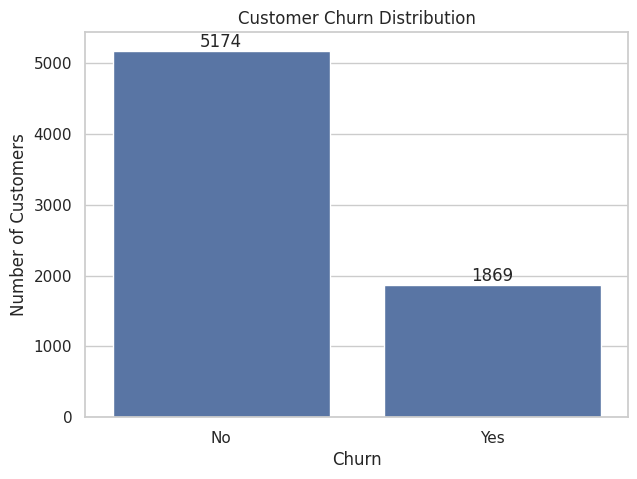

In [ ]:
churn_counts = df_clean["Churn"].value_counts()

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df_clean,
    x="Churn"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container)

plt.show()

In [ ]:
churn_rate = (
    df_clean["Churn"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

churn_rate

,proportion
Churn,
No,73.46
Yes,26.54


## Churn vs Contract

In [ ]:
contract_churn = pd.crosstab(
    df_clean["Contract"],
    df_clean["Churn"],
    normalize="index"
) * 100

contract_churn

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


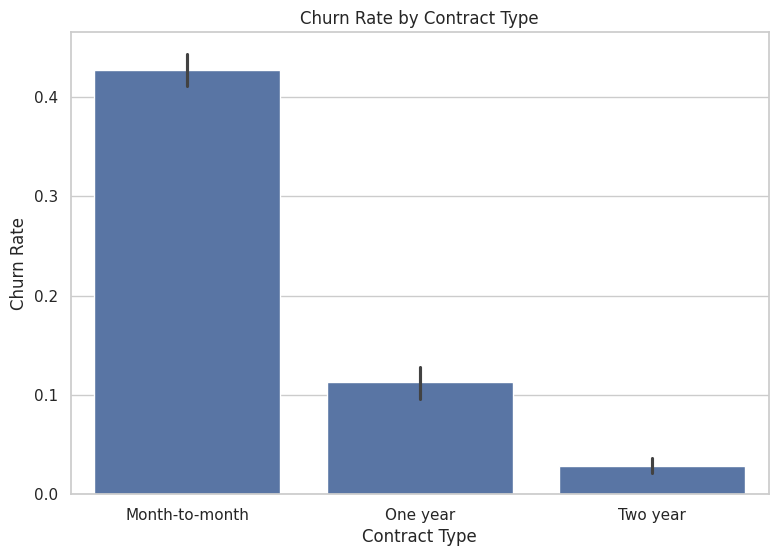

In [ ]:
# Visualization
plt.figure(figsize=(9, 6))

sns.barplot(
    data=df_clean,
    x="Contract",
    y=df_clean["Churn"].eq("Yes").astype(int)
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate")

plt.show()

## Churn vs Tenure

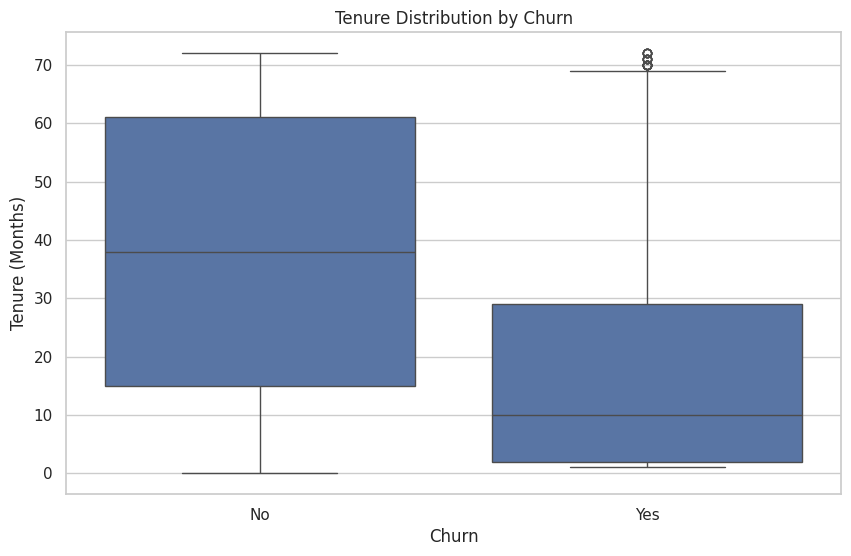

In [ ]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_clean,
    x="Churn",
    y="tenure"
)

plt.title("Tenure Distribution by Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.show()

In [ ]:
tenure_churn = (
    df_clean
    .groupby("Churn")["tenure"]
    .agg(["mean", "median", "min", "max"])
)

tenure_churn

,mean,median,min,max
Churn,,,,
No,37.569965,38.0,0,72
Yes,17.979133,10.0,1,72


## Churn vs Monthly Charges

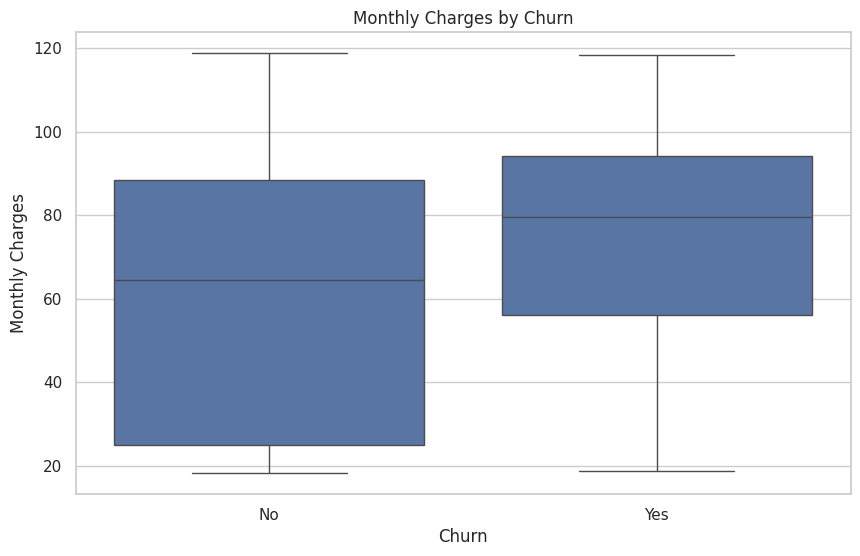

In [ ]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_clean,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges by Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

## Churn vs Internet Service

In [ ]:
internet_churn = pd.crosstab(
    df_clean["InternetService"],
    df_clean["Churn"],
    normalize="index"
) * 100

internet_churn

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


## Churn vs Payment Method

In [ ]:
payment_churn = pd.crosstab(
    df_clean["PaymentMethod"],
    df_clean["Churn"],
    normalize="index"
) * 100

payment_churn

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


# Feature Engineering

## Feature 1 — Customer Tenure Group

In [ ]:
df_clean["tenure_group"] = pd.cut(
    df_clean["tenure"],
    bins=[-1, 6, 12, 24, 48, 72],
    labels=[
        "0-6 months",
        "7-12 months",
        "13-24 months",
        "25-48 months",
        "49-72 months"
    ]
)

## Feature 2 — Average Historical Monthly Spend

In [ ]:
df_clean["avg_monthly_spend"] = np.where(
    df_clean["tenure"] > 0,
    df_clean["TotalCharges"] / df_clean["tenure"],
    0
)

## Feature 3 — Number of Services

In [ ]:
service_cols = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

df_clean["num_services"] = (
    df_clean[service_cols]
    .eq("Yes")
    .sum(axis=1)
)

## Feature 4 — Security Services

In [ ]:
df_clean["num_security_services"] = (
    df_clean[
        ["OnlineSecurity", "DeviceProtection", "TechSupport"]
    ]
    .eq("Yes")
    .sum(axis=1)
)

## Feature 5 — Streaming Services

In [ ]:
df_clean["num_streaming_services"] = (
    df_clean[
        ["StreamingTV", "StreamingMovies"]
    ]
    .eq("Yes")
    .sum(axis=1)
)

## Feature 6 — Is Month-to-Month

In [ ]:
df_clean["is_month_to_month"] = (
    df_clean["Contract"] == "Month-to-month"
).astype(int)

## Feature 7 — Is Long-Term Contract

In [ ]:
df_clean["is_long_term_contract"] = (
    df_clean["Contract"].isin(["One year", "Two year"])
).astype(int)

## Feature 8 — Is Electronic Check

In [ ]:
df_clean["is_electronic_check"] = (
    df_clean["PaymentMethod"] == "Electronic check"
).astype(int)

## Feature 9 — Fiber Optic

In [ ]:
df_clean["is_fiber_optic"] = (
    df_clean["InternetService"] == "Fiber optic"
).astype(int)

## Feature 10 — Has Partner + Dependents

In [ ]:
df_clean["has_family"] = (
    (df_clean["Partner"] == "Yes") |
    (df_clean["Dependents"] == "Yes")
).astype(int)

## Feature 11 — Total Number of Services

In [ ]:
df_clean["total_services"] = (
    (df_clean["PhoneService"] == "Yes").astype(int)
    +
    (df_clean["InternetService"] != "No").astype(int)
    +
    df_clean["num_services"]
)

## Feature Validation

In [ ]:
df_clean[
    [
        "tenure",
        "tenure_group",
        "TotalCharges",
        "avg_monthly_spend",
        "num_services",
        "num_security_services",
        "num_streaming_services",
        "is_month_to_month",
        "is_long_term_contract",
        "is_electronic_check",
        "is_fiber_optic",
        "has_family",
        "total_services"
    ]
].head(10)

,tenure,tenure_group,TotalCharges,avg_monthly_spend,num_services,num_security_services,num_streaming_services,is_month_to_month,is_long_term_contract,is_electronic_check,is_fiber_optic,has_family,total_services
0,1,0-6 months,29.85,29.850000,1,0,0,1,0,1,0,1,2
1,34,25-48 months,1889.50,55.573529,2,2,0,0,1,0,0,0,4
2,2,0-6 months,108.15,54.075000,2,1,0,1,0,0,0,0,4
3,45,25-48 months,1840.75,40.905556,3,3,0,0,1,0,0,0,4
4,2,0-6 months,151.65,75.825000,0,0,0,1,0,1,1,0,2
5,8,7-12 months,820.50,102.562500,3,1,2,1,0,1,1,0,5
6,22,13-24 months,1949.40,88.609091,2,0,1,1,0,0,1,1,4
7,10,7-12 months,301.90,30.190000,1,1,0,1,0,0,0,0,2
8,28,25-48 months,3046.05,108.787500,4,2,2,1,0,1,1,1,6
9,62,49-72 months,3487.95,56.257258,2,1,0,0,1,0,0,1,4


In [ ]:
df_clean[
    [
        "avg_monthly_spend",
        "num_services",
        "num_security_services",
        "num_streaming_services",
        "total_services"
    ]
].describe().T

,count,mean,std,min,25%,50%,75%,max
avg_monthly_spend,7043.0,64.698218,30.270670,0.0,35.649,70.3,90.174158,121.4
num_services,7043.0,2.037910,1.847682,0.0,0.000,2.0,3.000000,6.0
num_security_services,7043.0,0.920772,1.021759,0.0,0.000,1.0,2.000000,3.0
num_streaming_services,7043.0,0.772256,0.852573,0.0,0.000,0.0,2.000000,2.0
total_services,7043.0,3.724407,2.100232,1.0,2.000,4.0,5.000000,8.0


In [ ]:
df_clean.shape

(7043, 32)

In [ ]:
df_clean.head().T

,0,1,2,3,4
customerID,7590-VHVEG,5575-GNVDE,3668-QPYBK,7795-CFOCW,9237-HQITU
gender,Female,Male,Male,Male,Female
SeniorCitizen,0,0,0,0,0
Partner,Yes,No,No,No,No
Dependents,No,No,No,No,No
tenure,1,34,2,45,2
PhoneService,No,Yes,Yes,No,Yes
MultipleLines,No phone service,No,No,No phone service,No
InternetService,DSL,DSL,DSL,DSL,Fiber optic
OnlineSecurity,No,Yes,Yes,Yes,No


In [ ]:
df_clean[
    [
        "avg_monthly_spend",
        "num_services",
        "num_security_services",
        "num_streaming_services",
        "total_services"
    ]
].describe().T

,count,mean,std,min,25%,50%,75%,max
avg_monthly_spend,7043.0,64.698218,30.270670,0.0,35.649,70.3,90.174158,121.4
num_services,7043.0,2.037910,1.847682,0.0,0.000,2.0,3.000000,6.0
num_security_services,7043.0,0.920772,1.021759,0.0,0.000,1.0,2.000000,3.0
num_streaming_services,7043.0,0.772256,0.852573,0.0,0.000,0.0,2.000000,2.0
total_services,7043.0,3.724407,2.100232,1.0,2.000,4.0,5.000000,8.0


## Step 1 — Drop Customer ID + Encode Target

In [ ]:
# Create modeling dataset

model_df = df_clean.copy()

# Remove identifier
model_df = model_df.drop(columns=["customerID"])

# Encode target
model_df["Churn"] = model_df["Churn"].map({
    "No": 0,
    "Yes": 1
})

print(model_df.shape)
print(model_df["Churn"].value_counts())

(7043, 31)
Churn
0    5174
1    1869
Name: count, dtype: int64


## Step 2 — X and y

In [ ]:
X = model_df.drop(columns=["Churn"])
y = model_df["Churn"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (7043, 30)
y shape: (7043,)


## Step 3 — Train / Validation / Test

In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

## Step 4 — Verify the Split

In [ ]:
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (4930, 30)
Validation: (1056, 30)
Test: (1057, 30)


In [ ]:
def print_class_distribution(name, y_data):
    print(f"\n{name}")
    print(y_data.value_counts())
    print(
        (y_data.value_counts(normalize=True) * 100)
        .round(2)
    )

print_class_distribution("Train", y_train)
print_class_distribution("Validation", y_val)
print_class_distribution("Test", y_test)


Train
Churn
0    3622
1    1308
Name: count, dtype: int64
Churn
0    73.47
1    26.53
Name: proportion, dtype: float64

Validation
Churn
0    776
1    280
Name: count, dtype: int64
Churn
0    73.48
1    26.52
Name: proportion, dtype: float64

Test
Churn
0    776
1    281
Name: count, dtype: int64
Churn
0    73.42
1    26.58
Name: proportion, dtype: float64


## Step 5 — Features Type

In [ ]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numeric features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numeric features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'avg_monthly_spend', 'num_services', 'num_security_services', 'num_streaming_services', 'is_month_to_month', 'is_long_term_contract', 'is_electronic_check', 'is_fiber_optic', 'total_services', 'has_family']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'tenure_group']


## Step 6 —  Preprocessing Pipeline

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore",
            drop="if_binary"
        )
    )
])

preprocessor = ColumnTransformer([
    (
        "numeric",
        numeric_pipeline,
        numeric_features
    ),
    (
        "categorical",
        categorical_pipeline,
        categorical_features
    )
])

# Model: Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression

logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    (
        "model",
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        )
    )
])

## Train

In [ ]:
logistic_pipeline.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges',
                                                   'avg_monthly_spend',
                                                   'num_services',
                                                   'num_security_services',
                                                   'num_streaming_services',
                                                   'is_month_to_month',
                                                   'is_long_term_contract...
                                                                                 handle_unknown='ignore'))]),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod',
                                                   'tenure_group'])])),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=2000,
                                    random_state=42))])

## Validation Prediction

In [ ]:
y_val_pred = logistic_pipeline.predict(X_val)

y_val_proba = logistic_pipeline.predict_proba(
    X_val
)[:, 1]

## Evaluation

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

results = {
    "Accuracy": accuracy_score(y_val, y_val_pred),
    "Precision": precision_score(y_val, y_val_pred),
    "Recall": recall_score(y_val, y_val_pred),
    "F1": f1_score(y_val, y_val_pred),
    "ROC-AUC": roc_auc_score(y_val, y_val_proba),
    "PR-AUC": average_precision_score(y_val, y_val_proba)
}

pd.Series(results).round(4)

,0
Accuracy,0.7434
Precision,0.5098
Recall,0.8357
F1,0.6333
ROC-AUC,0.8500
PR-AUC,0.6521


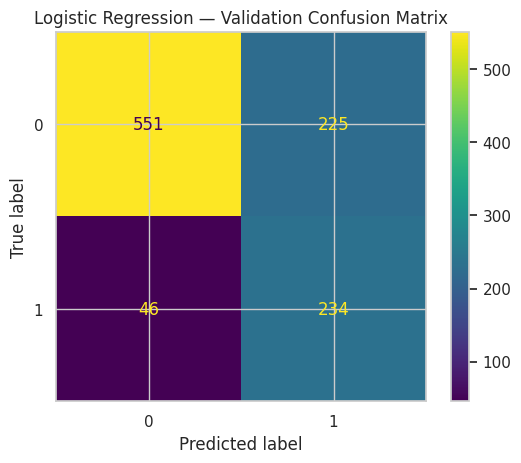

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred
)

plt.title("Logistic Regression — Validation Confusion Matrix")
plt.show()

In [ ]:
print(
    classification_report(
        y_val,
        y_val_pred,
        target_names=["No Churn", "Churn"]
    )
)

              precision    recall  f1-score   support

    No Churn       0.92      0.71      0.80       776
       Churn       0.51      0.84      0.63       280

    accuracy                           0.74      1056
   macro avg       0.72      0.77      0.72      1056
weighted avg       0.81      0.74      0.76      1056



# Model Benchmarking

# Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    (
        "model",
        RandomForestClassifier(
            n_estimators=500,
            max_depth=None,
            min_samples_split=5,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )
    )
])

In [ ]:
rf_pipeline.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges',
                                                   'avg_monthly_spend',
                                                   'num_services',
                                                   'num_security_services',
                                                   'num_streaming_services',
                                                   'is_month_to_month',
                                                   'is_long_term_contract...
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod',
                                                   'tenure_group'])])),
                ('model',
                 RandomForestClassifier(class_weight='balanced',
                                        min_samples_leaf=2, min_samples_split=5,
                                        n_estimators=500, n_jobs=-1,
                                        random_state=42))])

In [ ]:
y_val_pred_rf = rf_pipeline.predict(X_val)

y_val_proba_rf = rf_pipeline.predict_proba(
    X_val
)[:, 1]

In [ ]:
rf_results = {
    "Accuracy": accuracy_score(y_val, y_val_pred_rf),
    "Precision": precision_score(y_val, y_val_pred_rf),
    "Recall": recall_score(y_val, y_val_pred_rf),
    "F1": f1_score(y_val, y_val_pred_rf),
    "ROC-AUC": roc_auc_score(y_val, y_val_proba_rf),
    "PR-AUC": average_precision_score(y_val, y_val_proba_rf)
}

pd.Series(rf_results).round(4)

,0
Accuracy,0.7784
Precision,0.5728
Recall,0.6464
F1,0.6074
ROC-AUC,0.8349
PR-AUC,0.6190


In [ ]:
print(
    classification_report(
        y_val,
        y_val_pred_rf,
        target_names=["No Churn", "Churn"]
    )
)

              precision    recall  f1-score   support

    No Churn       0.87      0.83      0.85       776
       Churn       0.57      0.65      0.61       280

    accuracy                           0.78      1056
   macro avg       0.72      0.74      0.73      1056
weighted avg       0.79      0.78      0.78      1056



# XGBoost

In [ ]:
from xgboost import XGBClassifier

In [ ]:
xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    (
        "model",
        XGBClassifier(
            n_estimators=500,
            learning_rate=0.05,
            max_depth=5,
            min_child_weight=3,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        )
    )
])

In [ ]:
xgb_pipeline.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges',
                                                   'avg_monthly_spend',
                                                   'num_services',
                                                   'num_security_services',
                                                   'num_streaming_services',
                                                   'is_month_to_month',
                                                   'is_long_term_contract...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=5, max_leaves=None, min_child_weight=3,
                               missing=nan, monotone_constraints=None,
                               multi_strategy=None, n_estimators=500, n_jobs=-1,
                               num_parallel_tree=None, ...))])

In [ ]:
y_val_pred_xgb = xgb_pipeline.predict(X_val)

y_val_proba_xgb = xgb_pipeline.predict_proba(
    X_val
)[:, 1]

In [ ]:
xgb_results = {
    "Accuracy": accuracy_score(y_val, y_val_pred_xgb),
    "Precision": precision_score(y_val, y_val_pred_xgb),
    "Recall": recall_score(y_val, y_val_pred_xgb),
    "F1": f1_score(y_val, y_val_pred_xgb),
    "ROC-AUC": roc_auc_score(y_val, y_val_proba_xgb),
    "PR-AUC": average_precision_score(y_val, y_val_proba_xgb)
}

pd.Series(xgb_results).round(4)

,0
Accuracy,0.7775
Precision,0.5974
Recall,0.4929
F1,0.5401
ROC-AUC,0.8309
PR-AUC,0.6158


In [ ]:
print(
    classification_report(
        y_val,
        y_val_pred_xgb,
        target_names=["No Churn", "Churn"]
    )
)

              precision    recall  f1-score   support

    No Churn       0.83      0.88      0.85       776
       Churn       0.60      0.49      0.54       280

    accuracy                           0.78      1056
   macro avg       0.71      0.69      0.70      1056
weighted avg       0.77      0.78      0.77      1056



## "On this dataset and evaluation setup, Logistic Regression achieved the strongest ROC-AUC, PR-AUC, F1-score, and recall, while tree-based models achieved higher accuracy and precision but missed substantially more churn cases."

# LightGBM

In [ ]:
from lightgbm import LGBMClassifier

In [ ]:
lgbm_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    (
        "model",
        LGBMClassifier(
            n_estimators=500,
            learning_rate=0.03,
            num_leaves=31,
            max_depth=-1,
            min_child_samples=20,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_alpha=0.0,
            reg_lambda=0.0,
            random_state=42,
            n_jobs=-1,
            verbosity=-1
        )
    )
])

In [ ]:
lgbm_pipeline.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges',
                                                   'avg_monthly_spend',
                                                   'num_services',
                                                   'num_security_services',
                                                   'num_streaming_services',
                                                   'is_month_to_month',
                                                   'is_long_term_contract...
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod',
                                                   'tenure_group'])])),
                ('model',
                 LGBMClassifier(colsample_bytree=0.8, learning_rate=0.03,
                                n_estimators=500, n_jobs=-1, random_state=42,
                                subsample=0.8, verbosity=-1))])

In [ ]:
y_val_pred_lgbm = lgbm_pipeline.predict(X_val)

y_val_proba_lgbm = lgbm_pipeline.predict_proba(
    X_val
)[:, 1]

In [ ]:
lgbm_results = {
    "Accuracy": accuracy_score(y_val, y_val_pred_lgbm),
    "Precision": precision_score(y_val, y_val_pred_lgbm),
    "Recall": recall_score(y_val, y_val_pred_lgbm),
    "F1": f1_score(y_val, y_val_pred_lgbm),
    "ROC-AUC": roc_auc_score(y_val, y_val_proba_lgbm),
    "PR-AUC": average_precision_score(y_val, y_val_proba_lgbm)
}

pd.Series(lgbm_results).round(4)

,0
Accuracy,0.7917
Precision,0.6293
Recall,0.5214
F1,0.5703
ROC-AUC,0.8320
PR-AUC,0.6219


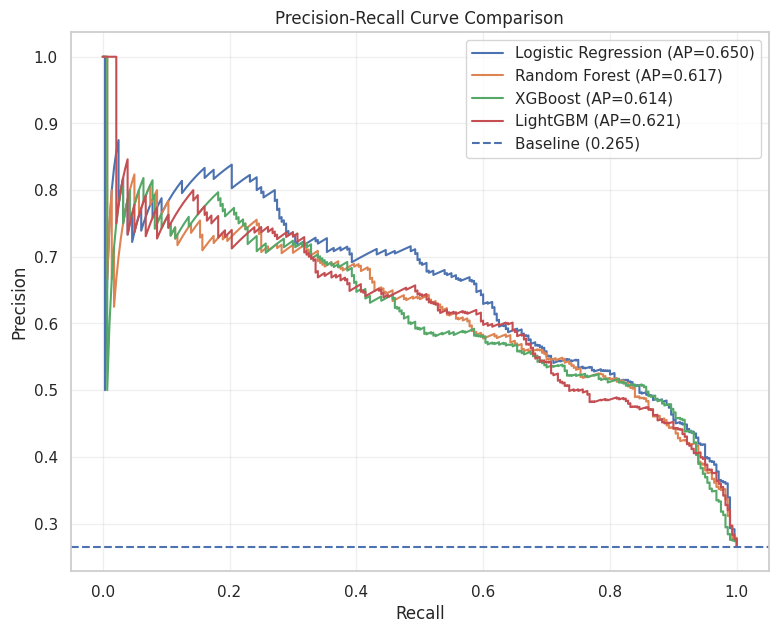

In [ ]:
from sklearn.metrics import precision_recall_curve, auc
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 7))

models_proba = {
    "Logistic Regression": y_val_proba,
    "Random Forest": y_val_proba_rf,
    "XGBoost": y_val_proba_xgb,
    "LightGBM": y_val_proba_lgbm
}

for name, probabilities in models_proba.items():

    precision, recall, _ = precision_recall_curve(
        y_val,
        probabilities
    )

    pr_auc = auc(recall, precision)

    plt.plot(
        recall,
        precision,
        label=f"{name} (AP={pr_auc:.3f})"
    )

# Random classifier baseline
baseline = y_val.mean()

plt.axhline(
    baseline,
    linestyle="--",
    label=f"Baseline ({baseline:.3f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

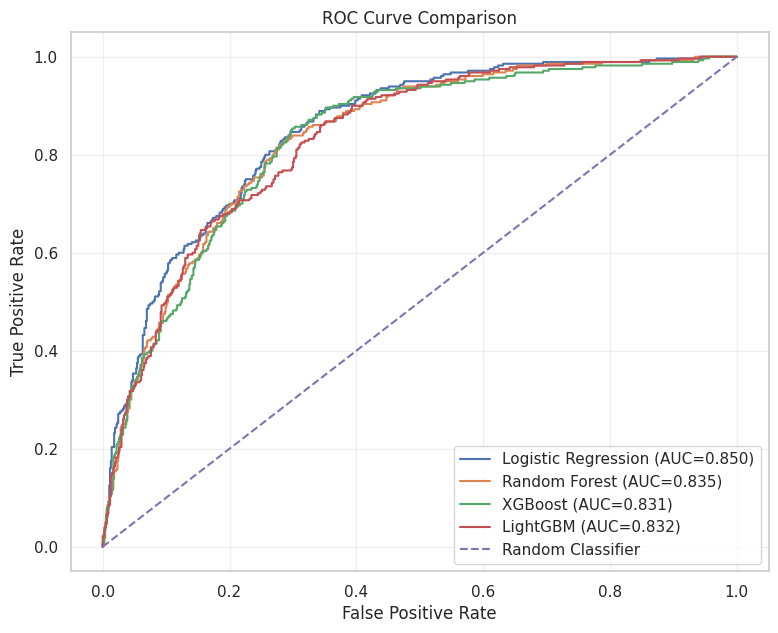

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(9, 7))

for name, probabilities in models_proba.items():

    fpr, tpr, _ = roc_curve(
        y_val,
        probabilities
    )

    roc_auc = roc_auc_score(
        y_val,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC={roc_auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

# CatBoost

In [ ]:
from catboost import CatBoostClassifier

X_train_cb = X_train.copy()
X_val_cb = X_val.copy()

categorical_features_cb = X_train_cb.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# CatBoost requires categorical values to be strings
for col in categorical_features_cb:
    X_train_cb[col] = X_train_cb[col].astype(str)
    X_val_cb[col] = X_val_cb[col].astype(str)

print("Categorical features:", categorical_features_cb)

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'tenure_group']


In [ ]:
catboost_model = CatBoostClassifier(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    loss_function="Logloss",
    eval_metric="AUC",
    auto_class_weights="Balanced",
    random_seed=42,
    verbose=False
)

In [ ]:
catboost_model.fit(
    X_train_cb,
    y_train,
    cat_features=categorical_features_cb,
    eval_set=(X_val_cb, y_val),
    early_stopping_rounds=50,
    verbose=False
)

CatBoostClassifier(auto_class_weights='Balanced', depth=6, eval_metric='AUC', iterations=500, learning_rate=0.05, loss_function='Logloss', random_seed=42, verbose=False)

In [ ]:
y_val_pred_cb = catboost_model.predict(
    X_val_cb
).astype(int).ravel()

y_val_proba_cb = catboost_model.predict_proba(
    X_val_cb
)[:, 1]

In [ ]:
catboost_results = {
    "Accuracy": accuracy_score(y_val, y_val_pred_cb),
    "Precision": precision_score(y_val, y_val_pred_cb),
    "Recall": recall_score(y_val, y_val_pred_cb),
    "F1": f1_score(y_val, y_val_pred_cb),
    "ROC-AUC": roc_auc_score(y_val, y_val_proba_cb),
    "PR-AUC": average_precision_score(y_val, y_val_proba_cb)
}

pd.Series(catboost_results).round(4)

,0
Accuracy,0.7557
Precision,0.5250
Recall,0.8250
F1,0.6417
ROC-AUC,0.8470
PR-AUC,0.6502


In [ ]:
print(
    classification_report(
        y_val,
        y_val_pred_cb,
        target_names=["No Churn", "Churn"]
    )
)

              precision    recall  f1-score   support

    No Churn       0.92      0.73      0.81       776
       Churn       0.53      0.82      0.64       280

    accuracy                           0.76      1056
   macro avg       0.72      0.78      0.73      1056
weighted avg       0.82      0.76      0.77      1056



In [ ]:
benchmark_results = pd.DataFrame({
    "Logistic Regression": results,
    "Random Forest": rf_results,
    "XGBoost": xgb_results,
    "LightGBM": lgbm_results,
    "CatBoost": catboost_results
}).T

benchmark_results = benchmark_results.round(4)

benchmark_results

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Logistic Regression,0.7434,0.5098,0.8357,0.6333,0.8500,0.6521
Random Forest,0.7784,0.5728,0.6464,0.6074,0.8349,0.6190
XGBoost,0.7775,0.5974,0.4929,0.5401,0.8309,0.6158
LightGBM,0.7917,0.6293,0.5214,0.5703,0.8320,0.6219
CatBoost,0.7557,0.5250,0.8250,0.6417,0.8470,0.6502


# Cross Validation للـLogistic

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [ ]:
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

In [ ]:
cv_results_lr = cross_validate(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

In [ ]:
lr_cv_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC",
        "PR-AUC"
    ],
    "Mean": [
        cv_results_lr["test_accuracy"].mean(),
        cv_results_lr["test_precision"].mean(),
        cv_results_lr["test_recall"].mean(),
        cv_results_lr["test_f1"].mean(),
        cv_results_lr["test_roc_auc"].mean(),
        cv_results_lr["test_pr_auc"].mean()
    ],
    "Std": [
        cv_results_lr["test_accuracy"].std(),
        cv_results_lr["test_precision"].std(),
        cv_results_lr["test_recall"].std(),
        cv_results_lr["test_f1"].std(),
        cv_results_lr["test_roc_auc"].std(),
        cv_results_lr["test_pr_auc"].std()
    ]
})

lr_cv_summary.round(4)

,Metric,Mean,Std
0,Accuracy,0.7495,0.0177
1,Precision,0.5184,0.0215
2,Recall,0.8035,0.0234
3,F1,0.6301,0.0217
4,ROC-AUC,0.8453,0.0101
5,PR-AUC,0.6587,0.0120


# دلوقتي نعمل CV لـ CatBoost

In [ ]:
from sklearn.base import clone

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cb_cv_scores = {
    "Accuracy": [],
    "Precision": [],
    "Recall": [],
    "F1": [],
    "ROC-AUC": [],
    "PR-AUC": []
}

for fold, (train_idx, val_idx) in enumerate(
    skf.split(X_train_cb, y_train), 1
):

    X_tr = X_train_cb.iloc[train_idx].copy()
    X_va = X_train_cb.iloc[val_idx].copy()

    y_tr = y_train.iloc[train_idx]
    y_va = y_train.iloc[val_idx]

    model = CatBoostClassifier(
        iterations=500,
        learning_rate=0.05,
        depth=6,
        loss_function="Logloss",
        eval_metric="AUC",
        auto_class_weights="Balanced",
        random_seed=42,
        verbose=False
    )

    model.fit(
        X_tr,
        y_tr,
        cat_features=categorical_features_cb,
        verbose=False
    )

    pred = model.predict(X_va).astype(int).ravel()
    proba = model.predict_proba(X_va)[:, 1]

    cb_cv_scores["Accuracy"].append(
        accuracy_score(y_va, pred)
    )

    cb_cv_scores["Precision"].append(
        precision_score(y_va, pred)
    )

    cb_cv_scores["Recall"].append(
        recall_score(y_va, pred)
    )

    cb_cv_scores["F1"].append(
        f1_score(y_va, pred)
    )

    cb_cv_scores["ROC-AUC"].append(
        roc_auc_score(y_va, proba)
    )

    cb_cv_scores["PR-AUC"].append(
        average_precision_score(y_va, proba)
    )

    print(f"Fold {fold} completed")

Fold 1 completed
Fold 2 completed
Fold 3 completed
Fold 4 completed
Fold 5 completed


In [ ]:
cb_cv_summary = pd.DataFrame({
    "Metric": cb_cv_scores.keys(),
    "Mean": [
        np.mean(scores)
        for scores in cb_cv_scores.values()
    ],
    "Std": [
        np.std(scores)
        for scores in cb_cv_scores.values()
    ]
})

cb_cv_summary.round(4)

,Metric,Mean,Std
0,Accuracy,0.7604,0.0201
1,Precision,0.5364,0.0298
2,Recall,0.7423,0.0217
3,F1,0.6223,0.0227
4,ROC-AUC,0.8413,0.0105
5,PR-AUC,0.6618,0.0219


# دلوقتي LightGBM CV

In [ ]:
cv_results_lgbm = cross_validate(
    lgbm_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

In [ ]:
lgbm_cv_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC",
        "PR-AUC"
    ],
    "Mean": [
        cv_results_lgbm["test_accuracy"].mean(),
        cv_results_lgbm["test_precision"].mean(),
        cv_results_lgbm["test_recall"].mean(),
        cv_results_lgbm["test_f1"].mean(),
        cv_results_lgbm["test_roc_auc"].mean(),
        cv_results_lgbm["test_pr_auc"].mean()
    ],
    "Std": [
        cv_results_lgbm["test_accuracy"].std(),
        cv_results_lgbm["test_precision"].std(),
        cv_results_lgbm["test_recall"].std(),
        cv_results_lgbm["test_f1"].std(),
        cv_results_lgbm["test_roc_auc"].std(),
        cv_results_lgbm["test_pr_auc"].std()
    ]
})

lgbm_cv_summary.round(4)

,Metric,Mean,Std
0,Accuracy,0.7917,0.0066
1,Precision,0.6297,0.0145
2,Recall,0.5214,0.0201
3,F1,0.5703,0.0165
4,ROC-AUC,0.8318,0.0119
5,PR-AUC,0.6368,0.0187


# Hyperparameter Optimization

# نبدأ بـ Logistic Regression + RandomizedSearchCV

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
import numpy as np

lr_param_grid = {
    "model__C": np.logspace(-3, 2, 30),
    "model__solver": ["liblinear", "lbfgs"],
    "model__class_weight": ["balanced", None]
}

In [ ]:
lr_random_search = RandomizedSearchCV(
    estimator=logistic_pipeline,
    param_distributions=lr_param_grid,
    n_iter=20,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

In [ ]:
lr_random_search.fit(
    X_train,
    y_train
)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('numeric',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median')),
                                                                                               ('scaler',
                                                                                                StandardScaler())]),
                                                                               ['SeniorCitizen',
                                                                                'tenure',
                                                                                'MonthlyCharges',
                                                                                'TotalCharges',
                                                                                'avg_monthly_spend',
                                                                                'num_services',
                                                                                'n...
       1.17210230e-01, 1.74332882e-01, 2.59294380e-01, 3.85662042e-01,
       5.73615251e-01, 8.53167852e-01, 1.26896100e+00, 1.88739182e+00,
       2.80721620e+00, 4.17531894e+00, 6.21016942e+00, 9.23670857e+00,
       1.37382380e+01, 2.04335972e+01, 3.03919538e+01, 4.52035366e+01,
       6.72335754e+01, 1.00000000e+02]),
                                        'model__class_weight': ['balanced',
                                                                None],
                                        'model__solver': ['liblinear',
                                                          'lbfgs']},
                   random_state=42, scoring='average_precision', verbose=1)

In [ ]:
print("Best Parameters:")
print(lr_random_search.best_params_)

print("\nBest CV PR-AUC:")
print(round(lr_random_search.best_score_, 4))

Best Parameters:
{'model__solver': 'lbfgs', 'model__class_weight': None, 'model__C': np.float64(0.07880462815669913)}

Best CV PR-AUC:
0.6607


# ثبت Optuna

In [ ]:
!pip install -q optuna

In [ ]:
import optuna
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import average_precision_score
from catboost import CatBoostClassifier

In [ ]:
def objective_catboost(trial):

    params = {
        "iterations": trial.suggest_int(
            "iterations", 300, 1200
        ),

        "learning_rate": trial.suggest_float(
            "learning_rate", 0.01, 0.15, log=True
        ),

        "depth": trial.suggest_int(
            "depth", 4, 10
        ),

        "l2_leaf_reg": trial.suggest_float(
            "l2_leaf_reg", 1, 20, log=True
        ),

        "random_strength": trial.suggest_float(
            "random_strength", 0, 3
        ),

        "bagging_temperature": trial.suggest_float(
            "bagging_temperature", 0, 5
        ),

        "loss_function": "Logloss",
        "eval_metric": "AUC",
        "auto_class_weights": "Balanced",
        "random_seed": 42,
        "verbose": False,
        "thread_count": -1
    }

    skf = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    scores = []

    for train_idx, val_idx in skf.split(
        X_train_cb,
        y_train
    ):

        X_tr = X_train_cb.iloc[train_idx].copy()
        X_va = X_train_cb.iloc[val_idx].copy()

        y_tr = y_train.iloc[train_idx]
        y_va = y_train.iloc[val_idx]

        model = CatBoostClassifier(**params)

        model.fit(
            X_tr,
            y_tr,
            cat_features=categorical_features_cb,
            verbose=False
        )

        probabilities = model.predict_proba(
            X_va
        )[:, 1]

        score = average_precision_score(
            y_va,
            probabilities
        )

        scores.append(score)

    return np.mean(scores)

# شغل الـOptimization

In [ ]:
study_cb = optuna.create_study(
    direction="maximize",
    study_name="catboost_churn_pr_auc"
)

study_cb.optimize(
    objective_catboost,
    n_trials=30,
    show_progress_bar=True
)

[I 2026-08-13 13:19:49,752] A new study created in memory with name: catboost_churn_pr_auc


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-08-13 13:20:30,296] Trial 0 finished with value: 0.6644302944458428 and parameters: {'iterations': 594, 'learning_rate': 0.0340608536265805, 'depth': 5, 'l2_leaf_reg': 2.5752911569706365, 'random_strength': 0.5744810611395481, 'bagging_temperature': 1.6990490474979514}. Best is trial 0 with value: 0.6644302944458428.
[I 2026-08-13 13:21:10,614] Trial 1 finished with value: 0.6577307686561278 and parameters: {'iterations': 681, 'learning_rate': 0.06815721623699042, 'depth': 6, 'l2_leaf_reg': 7.54617541481899, 'random_strength': 2.2306352931657556, 'bagging_temperature': 2.4316308762011865}. Best is trial 0 with value: 0.6644302944458428.
[I 2026-08-13 13:22:46,089] Trial 2 finished with value: 0.661710739466209 and parameters: {'iterations': 594, 'learning_rate': 0.021982329890255864, 'depth': 9, 'l2_leaf_reg': 10.115495256776537, 'random_strength': 0.8339251278024948, 'bagging_temperature': 4.25209907657113}. Best is trial 0 with value: 0.6644302944458428.
[I 2026-08-13 13:23:5

In [ ]:
print("Best PR-AUC:")
print(round(study_cb.best_value, 4))

print("\nBest Parameters:")
for key, value in study_cb.best_params.items():
    print(f"{key}: {value}")

Best PR-AUC:
0.6692

Best Parameters:
iterations: 312
learning_rate: 0.01960388432707608
depth: 5
l2_leaf_reg: 2.042378638672651
random_strength: 0.26499544782255396
bagging_temperature: 1.1550501284170471


In [ ]:
best_cb_model = CatBoostClassifier(
    iterations=312,
    learning_rate=0.01960388432707608,
    depth=5,
    l2_leaf_reg=2.042378638672651,
    random_strength=0.26499544782255396,
    bagging_temperature=1.1550501284170471,
    loss_function="Logloss",
    eval_metric="AUC",
    auto_class_weights="Balanced",
    random_seed=42,
    verbose=False,
    thread_count=-1
)

In [ ]:
optimized_cb_scores = {
    "Accuracy": [],
    "Precision": [],
    "Recall": [],
    "F1": [],
    "ROC-AUC": [],
    "PR-AUC": []
}

for fold, (train_idx, val_idx) in enumerate(
    skf.split(X_train_cb, y_train), 1
):

    X_tr = X_train_cb.iloc[train_idx].copy()
    X_va = X_train_cb.iloc[val_idx].copy()

    y_tr = y_train.iloc[train_idx]
    y_va = y_train.iloc[val_idx]

    model = CatBoostClassifier(
        **study_cb.best_params,
        loss_function="Logloss",
        eval_metric="AUC",
        auto_class_weights="Balanced",
        random_seed=42,
        verbose=False,
        thread_count=-1
    )

    model.fit(
        X_tr,
        y_tr,
        cat_features=categorical_features_cb,
        verbose=False
    )

    pred = model.predict(X_va).astype(int).ravel()
    proba = model.predict_proba(X_va)[:, 1]

    optimized_cb_scores["Accuracy"].append(
        accuracy_score(y_va, pred)
    )

    optimized_cb_scores["Precision"].append(
        precision_score(y_va, pred)
    )

    optimized_cb_scores["Recall"].append(
        recall_score(y_va, pred)
    )

    optimized_cb_scores["F1"].append(
        f1_score(y_va, pred)
    )

    optimized_cb_scores["ROC-AUC"].append(
        roc_auc_score(y_va, proba)
    )

    optimized_cb_scores["PR-AUC"].append(
        average_precision_score(y_va, proba)
    )

In [ ]:
optimized_cb_summary = pd.DataFrame({
    "Metric": optimized_cb_scores.keys(),
    "Mean": [
        np.mean(v)
        for v in optimized_cb_scores.values()
    ],
    "Std": [
        np.std(v)
        for v in optimized_cb_scores.values()
    ]
})

optimized_cb_summary.round(4)

,Metric,Mean,Std
0,Accuracy,0.7489,0.0234
1,Precision,0.5187,0.0298
2,Recall,0.8004,0.0216
3,F1,0.6290,0.0249
4,ROC-AUC,0.8483,0.0098
5,PR-AUC,0.6692,0.0188


# الخطوة الجاية: Optimized LightGBM

In [ ]:
def objective_lgbm(trial):

    params = {
        "n_estimators": trial.suggest_int(
            "n_estimators", 200, 1000
        ),

        "learning_rate": trial.suggest_float(
            "learning_rate", 0.01, 0.15, log=True
        ),

        "num_leaves": trial.suggest_int(
            "num_leaves", 15, 100
        ),

        "max_depth": trial.suggest_int(
            "max_depth", 3, 12
        ),

        "min_child_samples": trial.suggest_int(
            "min_child_samples", 10, 100
        ),

        "subsample": trial.suggest_float(
            "subsample", 0.6, 1.0
        ),

        "colsample_bytree": trial.suggest_float(
            "colsample_bytree", 0.6, 1.0
        ),

        "reg_alpha": trial.suggest_float(
            "reg_alpha", 1e-4, 10, log=True
        ),

        "reg_lambda": trial.suggest_float(
            "reg_lambda", 1e-4, 10, log=True
        ),

        "random_state": 42,
        "n_jobs": -1,
        "verbosity": -1
    }

    skf = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    scores = []

    for train_idx, val_idx in skf.split(X_train, y_train):

        X_tr = X_train.iloc[train_idx]
        X_va = X_train.iloc[val_idx]

        y_tr = y_train.iloc[train_idx]
        y_va = y_train.iloc[val_idx]

        model = clone(lgbm_pipeline)

        # لو الـpipeline عندك اسمه model:
        model.set_params(
            model__n_estimators=params["n_estimators"],
            model__learning_rate=params["learning_rate"],
            model__num_leaves=params["num_leaves"],
            model__max_depth=params["max_depth"],
            model__min_child_samples=params["min_child_samples"],
            model__subsample=params["subsample"],
            model__colsample_bytree=params["colsample_bytree"],
            model__reg_alpha=params["reg_alpha"],
            model__reg_lambda=params["reg_lambda"]
        )

        model.fit(X_tr, y_tr)

        proba = model.predict_proba(X_va)[:, 1]

        scores.append(
            average_precision_score(y_va, proba)
        )

    return np.mean(scores)

In [ ]:
study_lgbm = optuna.create_study(
    direction="maximize",
    study_name="lightgbm_churn_pr_auc"
)

study_lgbm.optimize(
    objective_lgbm,
    n_trials=30,
    show_progress_bar=True
)

[I 2026-08-13 13:44:26,410] A new study created in memory with name: lightgbm_churn_pr_auc


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-08-13 13:44:41,374] Trial 0 finished with value: 0.6701233647147928 and parameters: {'n_estimators': 617, 'learning_rate': 0.015754384344526976, 'num_leaves': 24, 'max_depth': 3, 'min_child_samples': 87, 'subsample': 0.9348427737948035, 'colsample_bytree': 0.9886284020446887, 'reg_alpha': 0.0024501436737695633, 'reg_lambda': 0.08608615821795851}. Best is trial 0 with value: 0.6701233647147928.
[I 2026-08-13 13:45:10,753] Trial 1 finished with value: 0.6391857461376158 and parameters: {'n_estimators': 546, 'learning_rate': 0.016070295891881782, 'num_leaves': 69, 'max_depth': 11, 'min_child_samples': 35, 'subsample': 0.9344732289321568, 'colsample_bytree': 0.9876191052947855, 'reg_alpha': 0.0001385245955595241, 'reg_lambda': 0.008067983149371998}. Best is trial 0 with value: 0.6701233647147928.
[I 2026-08-13 13:45:12,939] Trial 2 finished with value: 0.6344757783212758 and parameters: {'n_estimators': 700, 'learning_rate': 0.12857778982607915, 'num_leaves': 52, 'max_depth': 3, 'm

In [ ]:
print("Best PR-AUC:")
print(round(study_lgbm.best_value, 4))

print("\nBest Parameters:")

for key, value in study_lgbm.best_params.items():
    print(f"{key}: {value}")

Best PR-AUC:
0.6701

Best Parameters:
n_estimators: 617
learning_rate: 0.015754384344526976
num_leaves: 24
max_depth: 3
min_child_samples: 87
subsample: 0.9348427737948035
colsample_bytree: 0.9886284020446887
reg_alpha: 0.0024501436737695633
reg_lambda: 0.08608615821795851


# اعمل 5-Fold CV للـOptimized LightGBM باستخدام الـbest parameters.

In [ ]:
optimized_lgbm = clone(lgbm_pipeline)

optimized_lgbm.set_params(
    model__n_estimators=617,
    model__learning_rate=0.015754384344526976,
    model__num_leaves=24,
    model__max_depth=3,
    model__min_child_samples=87,
    model__subsample=0.9348427737948035,
    model__colsample_bytree=0.9886284020446887,
    model__reg_alpha=0.0024501436737695633,
    model__reg_lambda=0.08608615821795851
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges',
                                                   'avg_monthly_spend',
                                                   'num_services',
                                                   'num_security_services',
                                                   'num_streaming_services',
                                                   'is_month_to_month',
                                                   'is_long_term_contract...
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod',
                                                   'tenure_group'])])),
                ('model',
                 LGBMClassifier(colsample_bytree=0.9886284020446887,
                                learning_rate=0.015754384344526976, max_depth=3,
                                min_child_samples=87, n_estimators=617,
                                n_jobs=-1, num_leaves=24, random_state=42,
                                reg_alpha=0.0024501436737695633,
                                reg_lambda=0.08608615821795851,
                                subsample=0.9348427737948035, verbosity=-1))])

In [ ]:
optimized_lgbm_results = cross_validate(
    optimized_lgbm,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

In [ ]:
optimized_lgbm_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC",
        "PR-AUC"
    ],
    "Mean": [
        optimized_lgbm_results["test_accuracy"].mean(),
        optimized_lgbm_results["test_precision"].mean(),
        optimized_lgbm_results["test_recall"].mean(),
        optimized_lgbm_results["test_f1"].mean(),
        optimized_lgbm_results["test_roc_auc"].mean(),
        optimized_lgbm_results["test_pr_auc"].mean()
    ],
    "Std": [
        optimized_lgbm_results["test_accuracy"].std(),
        optimized_lgbm_results["test_precision"].std(),
        optimized_lgbm_results["test_recall"].std(),
        optimized_lgbm_results["test_f1"].std(),
        optimized_lgbm_results["test_roc_auc"].std(),
        optimized_lgbm_results["test_pr_auc"].std()
    ]
})

optimized_lgbm_summary.round(4)

,Metric,Mean,Std
0,Accuracy,0.8059,0.0050
1,Precision,0.6705,0.0157
2,Recall,0.5290,0.0204
3,F1,0.5910,0.0124
4,ROC-AUC,0.8463,0.0128
5,PR-AUC,0.6701,0.0241


# Threshold Analysis

In [ ]:
optimized_lgbm.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges',
                                                   'avg_monthly_spend',
                                                   'num_services',
                                                   'num_security_services',
                                                   'num_streaming_services',
                                                   'is_month_to_month',
                                                   'is_long_term_contract...
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod',
                                                   'tenure_group'])])),
                ('model',
                 LGBMClassifier(colsample_bytree=0.9886284020446887,
                                learning_rate=0.015754384344526976, max_depth=3,
                                min_child_samples=87, n_estimators=617,
                                n_jobs=-1, num_leaves=24, random_state=42,
                                reg_alpha=0.0024501436737695633,
                                reg_lambda=0.08608615821795851,
                                subsample=0.9348427737948035, verbosity=-1))])

In [ ]:
val_proba = optimized_lgbm.predict_proba(
    X_val
)[:, 1]

In [ ]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

threshold_results = []

thresholds = np.arange(
    0.10,
    0.71,
    0.01
)

for threshold in thresholds:

    val_pred = (
        val_proba >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val,
            val_pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y_val,
            val_pred,
            zero_division=0
        ),
        "F1": f1_score(
            y_val,
            val_pred,
            zero_division=0
        )
    })

threshold_df = pd.DataFrame(
    threshold_results
)

threshold_df.round(4)

,Threshold,Precision,Recall,F1
0,0.10,0.4030,0.9571,0.5672
1,0.11,0.4150,0.9500,0.5776
2,0.12,0.4244,0.9429,0.5854
3,0.13,0.4321,0.9429,0.5926
4,0.14,0.4381,0.9357,0.5968
...,...,...,...,...
56,0.66,0.7315,0.2821,0.4072
57,0.67,0.7255,0.2643,0.3874
58,0.68,0.7300,0.2607,0.3842
59,0.69,0.7396,0.2536,0.3777


In [ ]:
best_threshold_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

best_threshold_row

,19
Threshold,0.290000
Precision,0.533181
Recall,0.832143
F1,0.649930


In [ ]:
threshold_df.loc[
    threshold_df["F1"].idxmax()
]

,19
Threshold,0.290000
Precision,0.533181
Recall,0.832143
F1,0.649930


In [ ]:
threshold_df[
    threshold_df["Recall"] >= 0.80
].sort_values(
    "Precision",
    ascending=False
).head()

,Threshold,Precision,Recall,F1
20,0.30,0.535377,0.810714,0.644886
19,0.29,0.533181,0.832143,0.649930
18,0.28,0.529279,0.839286,0.649171
17,0.27,0.526667,0.846429,0.649315
16,0.26,0.518600,0.846429,0.643148


In [ ]:
threshold_df[
    threshold_df["Precision"] >= 0.60
].sort_values(
    "Recall",
    ascending=False
).head()

,Threshold,Precision,Recall,F1
35,0.45,0.600719,0.596429,0.598566
37,0.47,0.607692,0.564286,0.585185
38,0.48,0.621514,0.557143,0.587571
39,0.49,0.637500,0.546429,0.588462
40,0.50,0.647826,0.532143,0.584314


# Final Evaluation

Model:
Optimized LightGBM

Threshold:
0.29

## Train Final Model

In [ ]:
optimized_lgbm.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges',
                                                   'avg_monthly_spend',
                                                   'num_services',
                                                   'num_security_services',
                                                   'num_streaming_services',
                                                   'is_month_to_month',
                                                   'is_long_term_contract...
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod',
                                                   'tenure_group'])])),
                ('model',
                 LGBMClassifier(colsample_bytree=0.9886284020446887,
                                learning_rate=0.015754384344526976, max_depth=3,
                                min_child_samples=87, n_estimators=617,
                                n_jobs=-1, num_leaves=24, random_state=42,
                                reg_alpha=0.0024501436737695633,
                                reg_lambda=0.08608615821795851,
                                subsample=0.9348427737948035, verbosity=-1))])

In [ ]:
test_proba = optimized_lgbm.predict_proba(
    X_test
)[:, 1]

In [ ]:
FINAL_THRESHOLD = 0.29

test_pred = (
    test_proba >= FINAL_THRESHOLD
).astype(int)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

final_metrics = {
    "Accuracy": accuracy_score(
        y_test,
        test_pred
    ),

    "Precision": precision_score(
        y_test,
        test_pred
    ),

    "Recall": recall_score(
        y_test,
        test_pred
    ),

    "F1": f1_score(
        y_test,
        test_pred
    ),

    "ROC-AUC": roc_auc_score(
        y_test,
        test_proba
    ),

    "PR-AUC": average_precision_score(
        y_test,
        test_proba
    )
}

pd.Series(final_metrics).round(4)

,0
Accuracy,0.7663
Precision,0.5438
Recall,0.7509
F1,0.6308
ROC-AUC,0.8377
PR-AUC,0.6559


In [ ]:
print(
    classification_report(
        y_test,
        test_pred,
        target_names=[
            "No Churn",
            "Churn"
        ]
    )
)

              precision    recall  f1-score   support

    No Churn       0.90      0.77      0.83       776
       Churn       0.54      0.75      0.63       281

    accuracy                           0.77      1057
   macro avg       0.72      0.76      0.73      1057
weighted avg       0.80      0.77      0.78      1057



In [ ]:
cm = confusion_matrix(
    y_test,
    test_pred
)

cm

array([[599, 177],
       [ 70, 211]])

# SHAP

In [ ]:
!pip install -q shap

In [ ]:
import shap
import pandas as pd
import numpy as np

# Extract pipeline components
preprocessor = optimized_lgbm.named_steps["preprocessor"]
model = optimized_lgbm.named_steps["model"]

# Transform test data
X_test_processed = preprocessor.transform(X_test)

print("Processed shape:", X_test_processed.shape)

Processed shape: (1057, 55)


In [ ]:
feature_names = preprocessor.get_feature_names_out()

print("Number of features:", len(feature_names))
print(feature_names[:20])

Number of features: 55
['numeric__SeniorCitizen' 'numeric__tenure' 'numeric__MonthlyCharges'
 'numeric__TotalCharges' 'numeric__avg_monthly_spend'
 'numeric__num_services' 'numeric__num_security_services'
 'numeric__num_streaming_services' 'numeric__is_month_to_month'
 'numeric__is_long_term_contract' 'numeric__is_electronic_check'
 'numeric__is_fiber_optic' 'numeric__total_services' 'numeric__has_family'
 'categorical__gender_Male' 'categorical__Partner_Yes'
 'categorical__Dependents_Yes' 'categorical__PhoneService_Yes'
 'categorical__MultipleLines_No'
 'categorical__MultipleLines_No phone service']


In [ ]:
X_test_processed_df = pd.DataFrame(
    X_test_processed.toarray()
    if hasattr(X_test_processed, "toarray")
    else X_test_processed,
    columns=feature_names,
    index=X_test.index
)

X_test_processed_df.head()

,numeric__SeniorCitizen,numeric__tenure,numeric__MonthlyCharges,numeric__TotalCharges,numeric__avg_monthly_spend,numeric__num_services,numeric__num_security_services,numeric__num_streaming_services,numeric__is_month_to_month,numeric__is_long_term_contract,numeric__is_electronic_check,numeric__is_fiber_optic,numeric__total_services,numeric__has_family,categorical__gender_Male,categorical__Partner_Yes,categorical__Dependents_Yes,categorical__PhoneService_Yes,categorical__MultipleLines_No,categorical__MultipleLines_No phone service,categorical__MultipleLines_Yes,categorical__InternetService_DSL,categorical__InternetService_Fiber optic,categorical__InternetService_No,categorical__OnlineSecurity_No,categorical__OnlineSecurity_No internet service,categorical__OnlineSecurity_Yes,categorical__OnlineBackup_No,categorical__OnlineBackup_No internet service,categorical__OnlineBackup_Yes,categorical__DeviceProtection_No,categorical__DeviceProtection_No internet service,categorical__DeviceProtection_Yes,categorical__TechSupport_No,categorical__TechSupport_No internet service,categorical__TechSupport_Yes,categorical__StreamingTV_No,categorical__StreamingTV_No internet service,categorical__StreamingTV_Yes,categorical__StreamingMovies_No,categorical__StreamingMovies_No internet service,categorical__StreamingMovies_Yes,categorical__Contract_Month-to-month,categorical__Contract_One year,categorical__Contract_Two year,categorical__PaperlessBilling_Yes,categorical__PaymentMethod_Bank transfer (automatic),categorical__PaymentMethod_Credit card (automatic),categorical__PaymentMethod_Electronic check,categorical__PaymentMethod_Mailed check,categorical__tenure_group_0-6 months,categorical__tenure_group_13-24 months,categorical__tenure_group_25-48 months,categorical__tenure_group_49-72 months,categorical__tenure_group_7-12 months
1639,2.282338,-0.627791,-0.658058,-0.667964,-0.643296,-1.110506,-0.910059,-0.914164,0.907317,-0.907317,1.407357,-0.889255,-0.827742,-1.073265,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
3776,-0.438147,0.427239,-0.284389,0.038979,-0.305268,-0.573129,-0.910059,0.249790,-1.102150,1.102150,-0.710552,-0.889255,-0.354555,0.931736,1.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
805,-0.438147,1.604003,0.391855,1.381410,0.363722,0.501624,0.066136,1.413743,-1.102150,1.102150,-0.710552,-0.889255,0.591820,0.931736,0.0,1.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2923,-0.438147,0.873597,0.821740,1.031788,0.708212,0.501624,1.042331,0.249790,0.907317,-0.907317,-0.710552,1.124537,0.591820,-1.073265,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
5392,-0.438147,1.238800,-0.846547,0.040680,-0.883784,0.501624,1.042331,-0.914164,-1.102150,1.102150,-0.710552,-0.889255,0.118633,0.931736,1.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [ ]:
explainer = shap.TreeExplainer(model)

shap_values = explainer.shap_values(
    X_test_processed_df
)

In [ ]:
print(type(shap_values))
print(np.array(shap_values).shape)

<class 'numpy.ndarray'>
(1057, 55)


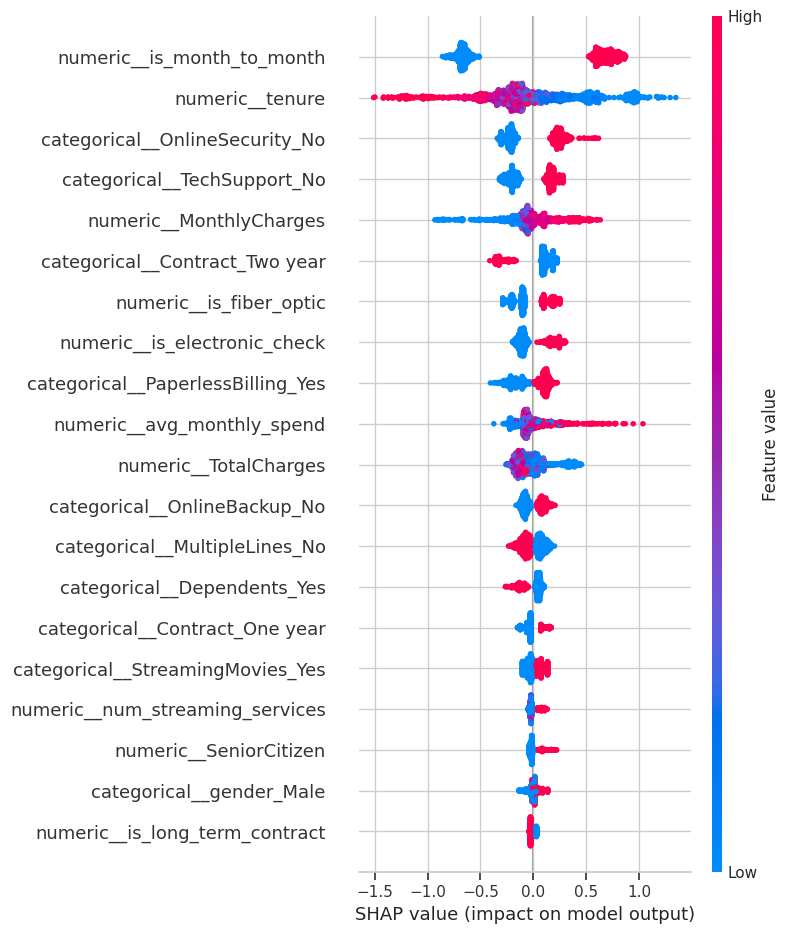

In [ ]:
shap.summary_plot(
    shap_values,
    X_test_processed_df,
    max_display=20
)

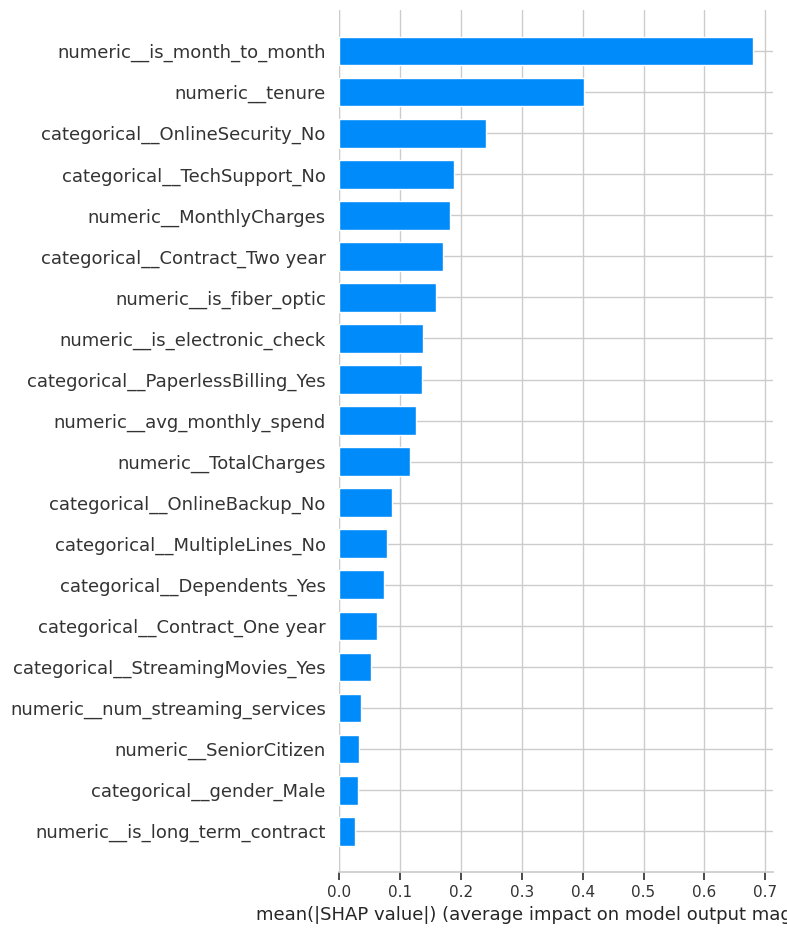

In [ ]:
shap.summary_plot(
    shap_values,
    X_test_processed_df,
    plot_type="bar",
    max_display=20
)

In [ ]:
# Select one churn customer from the test set
churn_idx = y_test[y_test == 1].index[0]

customer = X_test.loc[[churn_idx]]

customer

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,tenure_group,avg_monthly_spend,num_services,num_security_services,num_streaming_services,is_month_to_month,is_long_term_contract,is_electronic_check,is_fiber_optic,total_services,has_family
1639,Male,1,No,No,17,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,45.05,770.6,13-24 months,45.329412,0,0,0,1,0,1,0,2,0


In [ ]:
customer_probability = optimized_lgbm.predict_proba(
    customer
)[0, 1]

print(f"Churn Probability: {customer_probability:.2%}")

Churn Probability: 34.84%


In [ ]:
# Transform the selected customer
customer_processed = preprocessor.transform(customer)

customer_processed_df = pd.DataFrame(
    customer_processed.toarray()
    if hasattr(customer_processed, "toarray")
    else customer_processed,
    columns=feature_names,
    index=customer.index
)

customer_processed_df

,numeric__SeniorCitizen,numeric__tenure,numeric__MonthlyCharges,numeric__TotalCharges,numeric__avg_monthly_spend,numeric__num_services,numeric__num_security_services,numeric__num_streaming_services,numeric__is_month_to_month,numeric__is_long_term_contract,numeric__is_electronic_check,numeric__is_fiber_optic,numeric__total_services,numeric__has_family,categorical__gender_Male,categorical__Partner_Yes,categorical__Dependents_Yes,categorical__PhoneService_Yes,categorical__MultipleLines_No,categorical__MultipleLines_No phone service,categorical__MultipleLines_Yes,categorical__InternetService_DSL,categorical__InternetService_Fiber optic,categorical__InternetService_No,categorical__OnlineSecurity_No,categorical__OnlineSecurity_No internet service,categorical__OnlineSecurity_Yes,categorical__OnlineBackup_No,categorical__OnlineBackup_No internet service,categorical__OnlineBackup_Yes,categorical__DeviceProtection_No,categorical__DeviceProtection_No internet service,categorical__DeviceProtection_Yes,categorical__TechSupport_No,categorical__TechSupport_No internet service,categorical__TechSupport_Yes,categorical__StreamingTV_No,categorical__StreamingTV_No internet service,categorical__StreamingTV_Yes,categorical__StreamingMovies_No,categorical__StreamingMovies_No internet service,categorical__StreamingMovies_Yes,categorical__Contract_Month-to-month,categorical__Contract_One year,categorical__Contract_Two year,categorical__PaperlessBilling_Yes,categorical__PaymentMethod_Bank transfer (automatic),categorical__PaymentMethod_Credit card (automatic),categorical__PaymentMethod_Electronic check,categorical__PaymentMethod_Mailed check,categorical__tenure_group_0-6 months,categorical__tenure_group_13-24 months,categorical__tenure_group_25-48 months,categorical__tenure_group_49-72 months,categorical__tenure_group_7-12 months
1639,2.282338,-0.627791,-0.658058,-0.667964,-0.643296,-1.110506,-0.910059,-0.914164,0.907317,-0.907317,1.407357,-0.889255,-0.827742,-1.073265,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0


In [ ]:
customer_shap = explainer.shap_values(
    customer_processed_df
)

In [ ]:
print(type(customer_shap))
print(np.array(customer_shap).shape)

<class 'numpy.ndarray'>
(1, 55)


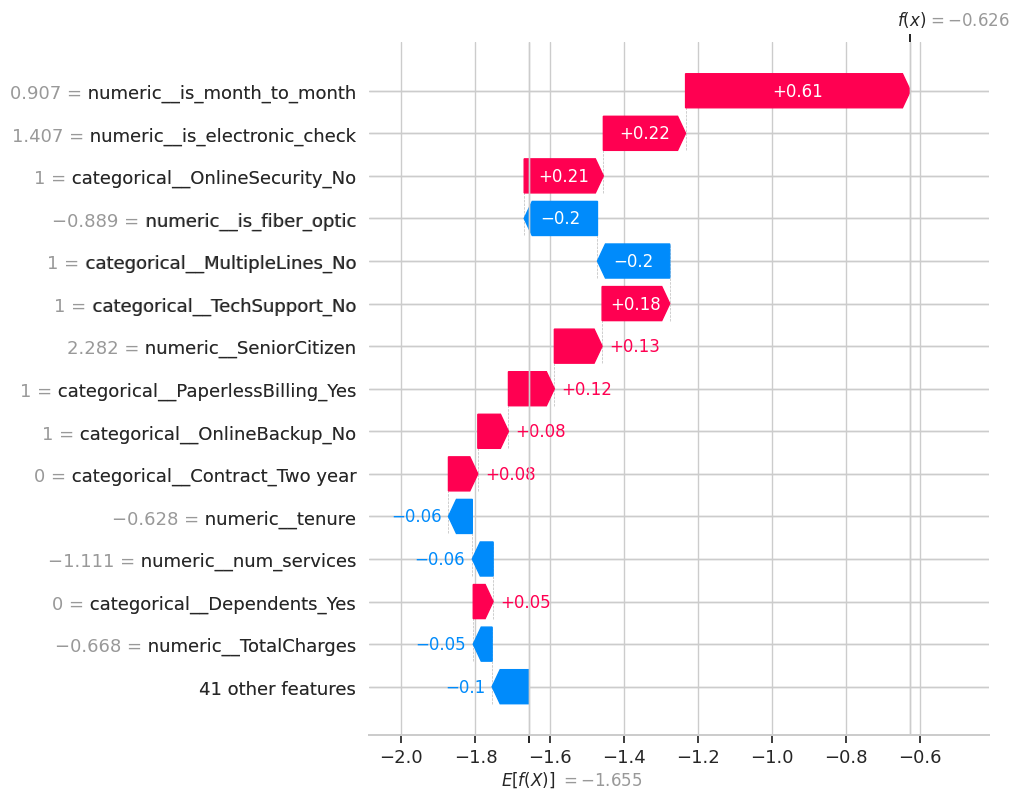

In [ ]:
customer_shap_values = customer_shap[0]

base_value = explainer.expected_value

if isinstance(base_value, (list, np.ndarray)):
    base_value = base_value[1] if np.ndim(base_value) > 0 else base_value

shap_explanation = shap.Explanation(
    values=customer_shap_values,
    base_values=base_value,
    data=customer_processed_df.iloc[0].values,
    feature_names=feature_names
)

shap.plots.waterfall(
    shap_explanation,
    max_display=15
)

Individual Prediction Explanation:
The model classified customer #1639 as high-risk with a predicted churn probability of 34.84%. The strongest contributors toward churn were month-to-month contract (+0.61 SHAP), electronic check payment (+0.22), lack of online security (+0.21), and lack of technical support (+0.18). Conversely, fiber-optic service and the absence of

In [ ]:
[name for name in globals() if not name.startswith("_")]

['In',
 'Out',
 'get_ipython',
 'exit',
 'quit',
 'os',
 'warnings',
 'np',
 'pd',
 'plt',
 'sns',
 'train_test_split',
 'StratifiedKFold',
 'cross_validate',
 'StandardScaler',
 'OneHotEncoder',
 'ColumnTransformer',
 'Pipeline',
 'SimpleImputer',
 'LogisticRegression',
 'RandomForestClassifier',
 'accuracy_score',
 'precision_score',
 'recall_score',
 'f1_score',
 'roc_auc_score',
 'average_precision_score',
 'confusion_matrix',
 'classification_report',
 'roc_curve',
 'precision_recall_curve',
 'RANDOM_STATE',
 'files',
 'uploaded',
 'io',
 'file_name',
 'df',
 'missing',
 'empty_strings',
 'total_charges_clean',
 'invalid_total_charges',
 'df_clean',
 'col',
 'phone_inconsistency',
 'internet_service_cols',
 'inconsistent',
 'numerical_cols',
 'churn_counts',
 'ax',
 'container',
 'churn_rate',
 'contract_churn',
 'tenure_churn',
 'internet_churn',
 'payment_churn',
 'service_cols',
 'model_df',
 'X',
 'y',
 'X_train',
 'X_temp',
 'y_train',
 'y_temp',
 'X_val',
 'X_test',
 'y_val'

In [ ]:
y_test_proba = test_proba

print("Number of probabilities:", len(y_test_proba))
print("Number of test samples:", len(y_test))
print("Final threshold:", FINAL_THRESHOLD)

Number of probabilities: 1057
Number of test samples: 1057
Final threshold: 0.29


In [ ]:
# ============================================================
# ERROR ANALYSIS
# ============================================================

error_analysis = X_test.copy()

error_analysis["actual"] = y_test.values
error_analysis["probability"] = test_proba
error_analysis["prediction"] = test_pred

error_analysis["error_type"] = "Correct"

# False Negative
error_analysis.loc[
    (error_analysis["actual"] == 1) &
    (error_analysis["prediction"] == 0),
    "error_type"
] = "False Negative"

# False Positive
error_analysis.loc[
    (error_analysis["actual"] == 0) &
    (error_analysis["prediction"] == 1),
    "error_type"
] = "False Positive"

print(error_analysis["error_type"].value_counts())

error_type
Correct           810
False Positive    177
False Negative     70
Name: count, dtype: int64


In [ ]:
false_negatives = error_analysis[
    error_analysis["error_type"] == "False Negative"
].copy()

print("False Negatives:", len(false_negatives))

false_negatives.sort_values(
    "probability",
    ascending=False
).head(20)

False Negatives: 70


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,tenure_group,avg_monthly_spend,num_services,num_security_services,num_streaming_services,is_month_to_month,is_long_term_contract,is_electronic_check,is_fiber_optic,total_services,has_family,actual,probability,prediction,error_type
2206,Male,1,Yes,No,57,Yes,Yes,Fiber optic,No,Yes,Yes,No,No,Yes,Month-to-month,Yes,Bank transfer (automatic),95.25,5427.05,49-72 months,95.211404,3,1,1,1,0,0,1,5,1,1,0.284514,0,False Negative
6641,Female,0,No,No,16,Yes,No,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,50.15,762.25,13-24 months,47.640625,1,1,0,1,0,1,0,3,0,1,0.278000,0,False Negative
6325,Female,0,Yes,Yes,17,Yes,No,Fiber optic,Yes,No,No,Yes,Yes,No,Month-to-month,No,Electronic check,91.85,1574.45,13-24 months,92.614706,3,2,1,1,0,1,1,5,1,1,0.272444,0,False Negative
5329,Female,0,Yes,No,25,No,No phone service,DSL,No,No,No,No,Yes,No,Month-to-month,Yes,Bank transfer (automatic),34.00,853.00,25-48 months,34.120000,1,0,1,1,0,0,0,2,1,1,0.270053,0,False Negative
223,Male,0,Yes,No,4,Yes,No,DSL,No,No,No,Yes,No,No,Month-to-month,No,Mailed check,50.05,179.35,0-6 months,44.837500,1,1,0,1,0,0,0,3,1,1,0.268682,0,False Negative
6388,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.40,20.40,0-6 months,20.400000,0,0,0,1,0,0,0,1,0,1,0.266248,0,False Negative
6972,Female,1,No,No,56,Yes,Yes,Fiber optic,No,Yes,Yes,Yes,Yes,Yes,One year,Yes,Electronic check,111.95,6418.90,49-72 months,114.623214,5,2,2,0,1,1,1,7,0,1,0.263341,0,False Negative
2379,Male,1,Yes,No,32,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,No,Bank transfer (automatic),106.35,3520.75,25-48 months,110.023438,4,1,2,1,0,0,1,6,1,1,0.263249,0,False Negative
523,Female,0,No,No,23,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,No,Bank transfer (automatic),75.60,1758.60,13-24 months,76.460870,0,0,0,1,0,0,1,2,0,1,0.259509,0,False Negative
3743,Male,0,No,Yes,4,Yes,No,DSL,Yes,No,No,No,No,No,Month-to-month,No,Electronic check,49.35,219.65,0-6 months,54.912500,1,1,0,1,0,1,0,3,1,1,0.253877,0,False Negative


In [ ]:
false_positives = error_analysis[
    error_analysis["error_type"] == "False Positive"
].copy()

print("False Positives:", len(false_positives))

false_positives.sort_values(
    "probability",
    ascending=False
).head(20)

False Positives: 177


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,tenure_group,avg_monthly_spend,num_services,num_security_services,num_streaming_services,is_month_to_month,is_long_term_contract,is_electronic_check,is_fiber_optic,total_services,has_family,actual,probability,prediction,error_type
2280,Female,1,No,No,8,Yes,Yes,Fiber optic,No,No,No,Yes,Yes,Yes,Month-to-month,Yes,Credit card (automatic),100.15,908.55,7-12 months,113.568750,3,1,2,1,0,0,1,5,0,0,0.875856,1,False Positive
5905,Male,0,No,No,1,Yes,No,Fiber optic,No,Yes,No,No,No,Yes,Month-to-month,Yes,Electronic check,85.00,85.00,0-6 months,85.000000,2,0,1,1,0,1,1,4,0,0,0.857983,1,False Positive
3633,Female,1,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,71.25,71.25,0-6 months,71.250000,0,0,0,1,0,1,1,2,0,0,0.842733,1,False Positive
486,Female,0,No,No,15,Yes,Yes,Fiber optic,No,Yes,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,100.15,1415.00,13-24 months,94.333333,3,0,2,1,0,1,1,5,0,0,0.783835,1,False Positive
4931,Male,0,Yes,No,15,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,103.45,1539.80,13-24 months,102.653333,4,2,2,1,0,1,1,6,1,0,0.772344,1,False Positive
4077,Female,1,Yes,Yes,14,Yes,Yes,Fiber optic,No,No,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,95.80,1346.30,13-24 months,96.164286,2,0,2,1,0,1,1,4,1,0,0.761386,1,False Positive
5250,Male,0,No,No,12,Yes,Yes,Fiber optic,No,No,No,No,Yes,Yes,Month-to-month,No,Electronic check,94.55,1173.55,7-12 months,97.795833,2,0,2,1,0,1,1,4,0,0,0.754921,1,False Positive
6284,Female,0,No,No,23,Yes,Yes,Fiber optic,No,No,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,93.50,2341.55,13-24 months,101.806522,2,0,2,1,0,1,1,4,0,0,0.750276,1,False Positive
352,Female,1,No,No,7,Yes,No,Fiber optic,No,No,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,89.15,574.35,7-12 months,82.050000,2,0,2,1,0,1,1,4,0,0,0.736400,1,False Positive
3981,Female,1,No,No,8,Yes,Yes,Fiber optic,No,No,No,No,No,Yes,Month-to-month,No,Electronic check,85.20,695.75,7-12 months,86.968750,1,0,1,1,0,1,1,3,0,0,0.734246,1,False Positive


In [166]:
churn_cases = error_analysis[
    error_analysis["actual"] == 1
].copy()

churn_cases["group"] = np.where(
    churn_cases["prediction"] == 1,
    "True Positive",
    "False Negative"
)

comparison = churn_cases.groupby("group")[
    [
        "tenure",
        "MonthlyCharges",
        "TotalCharges",
        "avg_monthly_spend",
        "num_services",
        "num_security_services",
        "num_streaming_services"
    ]
].agg(["mean", "median"])

comparison

tenure        MonthlyCharges         TotalCharges           \
                     mean median           mean  median         mean   median   
group                                                                           
False Negative  29.528571   24.5      62.301429  61.525  2321.732857  1559.25   
True Positive   13.137441    6.0      74.223460  78.050  1129.567536   461.70   

               avg_monthly_spend            num_services         \
                            mean     median         mean median   
group                                                             
False Negative         62.434705  61.332673     2.142857    2.0   
True Positive          74.060394  78.941667     1.417062    1.0   

               num_security_services        num_streaming_services         
                                mean median                   mean median  
group                                                                      
False Negative              1.028571    1.0               0.800000    0.0  
True Positive               0.440758    0.0               0.763033    1.0

In [167]:
pd.crosstab(
    churn_cases["Contract"],
    churn_cases["group"],
    normalize="columns"
).round(3)

group,False Negative,True Positive
Contract,,
Month-to-month,0.514,0.981
One year,0.414,0.019
Two year,0.071,0.000


In [168]:
pd.crosstab(
    churn_cases["PaymentMethod"],
    churn_cases["group"],
    normalize="columns"
).round(3)

group,False Negative,True Positive
PaymentMethod,,
Bank transfer (automatic),0.229,0.095
Credit card (automatic),0.214,0.104
Electronic check,0.314,0.664
Mailed check,0.243,0.137


In [169]:
pd.crosstab(
    churn_cases["InternetService"],
    churn_cases["group"],
    normalize="columns"
).round(3)

group,False Negative,True Positive
InternetService,,
DSL,0.400,0.218
Fiber optic,0.357,0.749
No,0.243,0.033


In [171]:
import joblib

# Save the trained pipeline
joblib.dump(
    optimized_lgbm,
    "telco_churn_lgbm_pipeline.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [172]:
FINAL_THRESHOLD = 0.29

In [173]:
import json

model_config = {
    "model": "LightGBM",
    "threshold": 0.29,
    "roc_auc": 0.8377,
    "pr_auc": 0.6559,
    "recall": 0.7509,
    "precision": 0.5438,
    "f1": 0.6308,
    "accuracy": 0.7663
}

with open("model_config.json", "w") as f:
    json.dump(model_config, f, indent=4)

print("Configuration saved!")

Configuration saved!


In [174]:
loaded_model = joblib.load(
    "telco_churn_lgbm_pipeline.pkl"
)

test_probability = loaded_model.predict_proba(X_test)[:, 1]

test_prediction = (
    test_probability >= 0.29
).astype(int)

print("First 10 probabilities:")
print(test_probability[:10])

print("\nFirst 10 predictions:")
print(test_prediction[:10])

First 10 probabilities:
[0.34842853 0.12191614 0.05951138 0.17632852 0.02411411 0.11861975
 0.00515146 0.08327646 0.08615261 0.85611801]

First 10 predictions:
[1 0 0 0 0 0 0 0 0 1]


In [175]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        test_prediction,
        target_names=["No Churn", "Churn"]
    )
)

              precision    recall  f1-score   support

    No Churn       0.90      0.77      0.83       776
       Churn       0.54      0.75      0.63       281

    accuracy                           0.77      1057
   macro avg       0.72      0.76      0.73      1057
weighted avg       0.80      0.77      0.78      1057



In [176]:
import os

os.makedirs("artifacts", exist_ok=True)

joblib.dump(
    optimized_lgbm,
    "artifacts/telco_churn_lgbm_pipeline.pkl"
)

with open("artifacts/model_config.json", "w") as f:
    json.dump(model_config, f, indent=4)

print("Artifacts created successfully.")

Artifacts created successfully.


In [177]:
print(type(optimized_lgbm))

<class 'sklearn.pipeline.Pipeline'>


In [178]:
from google.colab import files

files.download(
    "artifacts/telco_churn_lgbm_pipeline.pkl"
)

files.download(
    "artifacts/model_config.json"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>